# Imports

In [2]:
# GIS and Spatial Data Libraries
import rasterio
from rasterio.transform import xy
from rasterio.warp import transform_bounds
from rasterio.plot import show

import geopandas as gpd
import shapely
from shapely.geometry import Point
from shapely.geometry import box
import rioxarray
import xrspatial as xspd
from pyproj import Transformer
import pip 
import json

# Data Analysis and Machine Learning
import numpy as np
import pandas as pd
from scipy.stats import skew

# Data Visualization
import matplotlib.pyplot as plt

# Print verification to ensure everything loaded without errors
print("All libraries imported successfully")

All libraries imported successfully


# Data Cleaning

## OpenTopography DEM

In [3]:
# File Loading Validation
from pathlib import Path
import os

# Check for File Load Errors
print("Working directory:", Path.cwd())
print("Python executable:", os.sys.executable)
print("Datasets folder exists:", Path("Datasets").exists())

Working directory: c:\Users\matil\Documents\GitHub\GIS-Project
Python executable: c:\Users\matil\AppData\Local\Programs\Python\Python313\python.exe
Datasets folder exists: True


In [6]:
# Load .tif
tif_path = r"Datasets\rasters_CAMRDEM\DEM.tif"
src = rasterio.open(r"Datasets\rasters_CAMRDEM\DEM.tif")

# Raster Metadata
with rasterio.open(tif_path) as src:
    elevation_crs = src.crs
    elevation_transform = src.transform
    
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width:", src.width)
    print("Height:", src.height)
    print(src.tags())
    #print(src.crs.to_wkt())
    print("Resolution:", src.res)
    print("NoData value:", src.nodata)
    print("Transform:", src.transform)

    bounds_4326 = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

    bounds_EPSG_32610 = transform_bounds(
            src.crs,
            "EPSG:32610",
            *src.bounds
        )

    print("WGS84 bounds:", bounds_4326)

CRS: EPSG:3979
Bounds: BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)
Width: 666
Height: 895
{'AREA_OR_POINT': 'Area'}
Resolution: (30.0, 30.0)
NoData value: -32767.0
Transform: | 30.00, 0.00,-1980000.00|
| 0.00,-30.00, 500400.00|
| 0.00, 0.00, 1.00|
WGS84 bounds: (-123.29291260026993, 49.25527457420543, -122.8853009908351, 49.55076853448343)


In [7]:
# Extract bounds
west, south, east, north = bounds_4326

print("West:", west)
print("South:", south)
print("East:", east)
print("North:", north)

geometry = box(west, south, east, north)

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {},
        "geometry": geometry.__geo_interface__
    }]
}

with open("dem_AOI.geojson", "w") as f:
    json.dump(geojson, f, indent=2)

West: -123.29291260026993
South: 49.25527457420543
East: -122.8853009908351
North: 49.55076853448343


In [9]:
# Read band 1
src = rasterio.open(r"Datasets\rasters_CAMRDEM\DEM.tif")
with rasterio.open(tif_path) as src:
    elevation = src.read(1)
    elevation_transform = src.transform
    elevation_crs = src.crs

    print("Array type:", type(elevation))
    print("Array size:", elevation.size)
    print("Array shape:", elevation.shape)
    print("Minimum value:", elevation.min())
    print("Maximum value:", elevation.max())

Array type: <class 'numpy.ndarray'>
Array size: 596070
Array shape: (895, 666)
Minimum value: -32767.0
Maximum value: 1503.917


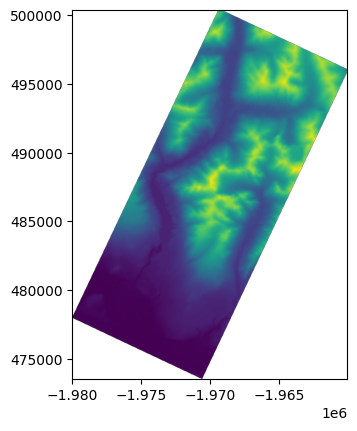

<Axes: >

In [10]:
# Data Mask
valid_mask = elevation != src.nodata
elevation_valid = np.where(
    valid_mask,
    elevation,
    np.nan
)

# Data Plot
show(elevation_valid, transform=src.transform)

## EarthEngine Sentinel-2, DWV1, and Landsat  Data

### EarthEngine Authentication and Bounds

In [13]:
import ee 

ee.Authenticate()
ee.Initialize(project="gis-project-510419")

In [22]:
print("Red band bounds:", src.bounds)
print("Red band CRS:", src.crs)

west_l2a, south_l2a, east_l2a, north_l2a = src.bounds
print("Bounding box coordinates:")
print("West:", west_l2a)
print("South:", south_l2a)
print("East:", east_l2a)
print("North:", north_l2a)

# Transform Coordinates
transformer_l2a = Transformer.from_crs(
    sentinel_2024_src.crs,
    "EPSG:4326",  
    always_xy=True
)

lon_west, lat_south = transformer_l2a.transform(west_l2a, south_l2a)
print(west_l2a, south_l2a)
print(lon_west, lat_south)

lon_east, lat_north = transformer_l2a.transform(east_l2a, north_l2a)
print(east_l2a, north_l2a)
print(lon_east, lat_north)


Red band bounds: BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)
Red band CRS: EPSG:3979
Bounding box coordinates:
West: -1980000.0
South: 473550.0
East: -1960020.0
North: 500400.0
-1980000.0 473550.0
-144.7966883725561 3.9768755675530607
-1960020.0 500400.0
-144.63593193828933 4.207199182461897


In [ ]:
xmin, ymin, xmax, ymax = bounds_EPSG_32610 

aoi_utm = ee.Geometry.Rectangle([xmin, ymin, xmax, ymax], "EPSG:32610", False)   # proj is the 2nd argument, geodesic the 3rd
print(aoi_utm.projection().getInfo())

{'type': 'Projection', 'crs': 'EPSG:32610', 'transform': [1, 0, 0, 0, 1, 0]}


In [14]:
aoi = ee.Geometry.Rectangle([
    lon_west,
    lat_south,
    lon_east,
    lat_north
])

print(aoi)

NameError: name 'lon_west' is not defined

### 2026 Sentinel Data

In [ ]:
sentinel_2026 = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate("2026-08-1","2026-08-31")
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 10))
)

print("Number of images:", sentinel_2026.size().getInfo())
print("Images:")
print(sentinel_2026.aggregate_array("system:index").getInfo())


Number of images: 6
Images:
['20260805T191909_20260805T193001_T10UDV', '20260807T190911_20260807T191738_T10UDV', '20260812T190909_20260812T191707_T10UDV', '20260817T190911_20260817T191923_T10UDV', '20260820T191911_20260820T192259_T10UDV', '20260825T191909_20260825T192922_T10UDV']


In [ ]:
sentinel_2026_image = ee.Image(sentinel_2026.toList(sentinel_2026.size()).get(1)) 
print(
    sentinel_2026_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE',
        'SENSING_ORBIT_NUMBER'
    ]).getInfo()
)

print(sentinel_2026_image.bandNames().getInfo())
print(sentinel_2026_image.bandNames().getInfo())

from IPython.display import Image, display

img = sentinel_2026_image            
url = img.select(["B4", "B3", "B2"]).getThumbURL({
    "region": aoi,                   
    "dimensions": 1000,              
    "min": 0, "max": 3000,           
    "format": "png",
})
display(Image(url=url))

{'CLOUDY_PIXEL_PERCENTAGE': 0.001403, 'DATATAKE_IDENTIFIER': 'GS2C_20260807T190911_010036_N05.12', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2C_MSIL2A_20260807T190911_N0512_R056_T10UDV_20260807T234017', 'SENSING_ORBIT_NUMBER': 56, 'system:index': '20260807T190911_20260807T191738_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


In [ ]:
sentinel_2026_bands = (
    sentinel_2026_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task_2 = ee.batch.Export.image.toDrive(
    image=sentinel_2026_bands,
    description="sentinel_l2a_20260807T190911_20260807T191738_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20260807T190911_20260807T191738_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_2.start()
print("Export started")

Export started


In [ ]:
print(task_2.status())

{'state': 'COMPLETED', 'description': 'sentinel_l2a_20260807T190911_20260807T191738_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792097775328, 'update_timestamp_ms': 1792098665466, 'start_timestamp_ms': 1792097782441, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/16PMye91hB5cePcHjvv1Tr8_qE50-lc8r'], 'attempt': 1, 'batch_eecu_usage_seconds': 382.712890625, 'id': 'FW4XNK7ABZVDMI2NK7NCNOZC', 'name': 'projects/gis-project-510419/operations/FW4XNK7ABZVDMI2NK7NCNOZC'}


In [15]:
sentinel_2026_data = r"Datasets\sentinel_l2a_20260807T190911_20260807T191738_T10UDV.tif"

with rasterio.open(sentinel_2026_data) as sentinel_2026_src:
    # Read each band from the Sentinel-2 multiband GeoTIFF

    band_index = {name: i + 1 for i, name in enumerate(sentinel_2026_src.descriptions)}

    sentinel_2026_B4_R = sentinel_2026_src.read(band_index["B4"])
    sentinel_2026_B8_NIR = sentinel_2026_src.read(band_index["B8"])
    sentinel_2026_SCL = sentinel_2026_src.read(band_index["SCL"])
    sentinel_2026_B2 = sentinel_2026_src.read(band_index["B2"])
    sentinel_2026_B3 = sentinel_2026_src.read(band_index["B3"])

    # Dataset-level metadata
    sentinel_2026_B4_transform = sentinel_2026_src.transform
    sentinel_2026_B4_crs = sentinel_2026_src.crs
    sentinel_2026_B4_nodata = sentinel_2026_src.nodatavals[0]
    sentinel_2026_B4_shape = sentinel_2026_B4_R.shape

    print("CRS:", sentinel_2026_src.crs)
    print("Bounds:", sentinel_2026_src.bounds)
    print("Width:", sentinel_2026_src.width)
    print("Height:", sentinel_2026_src.height)
    print("Tags:", sentinel_2026_src.tags())
    print("Resolution:", sentinel_2026_src.res)
    print("NoData value:", sentinel_2026_src.nodata)
    print("Transform:", sentinel_2026_src.transform)
    print("Descriptions:", sentinel_2026_src.descriptions)

    '''
    sentinel_2026_bounds_4326 = transform_bounds(
        sentinel_2026_src.crs,
        "EPSG:4326",
        *sentinel_2026_src.bounds
    )
    print("WGS84 bounds:", sentinel_2026_bounds_4326)
    '''

    print("B4 min/max:", np.min(sentinel_2026_B4_R), np.max(sentinel_2026_B4_R))
    print("B8 min/max:", np.min(sentinel_2026_B8_NIR), np.max(sentinel_2026_B8_NIR))
    print("B2 min/max:", np.min(sentinel_2026_B2), np.max(sentinel_2026_B2))
    print("B3 min/max:", np.min(sentinel_2026_B3), np.max(sentinel_2026_B3))
    print("SCL min/max:", np.min(sentinel_2026_SCL), np.max(sentinel_2026_SCL))

CRS: EPSG:32610
Bounds: BoundingBox(left=399940.0, bottom=5388440.0, right=510170.0, top=5501780.0)
Width: 11023
Height: 11334
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399940.00|
| 0.00,-10.00, 5501780.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL', 'B2', 'B3')
B4 min/max: 0 16797
B8 min/max: 0 16104
B2 min/max: 0 18701
B3 min/max: 0 17598
SCL min/max: 0 11


In [ ]:
# Sentinel-2 L2A SCL masking + NDVI
bad_classes_2026 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2026 = ~np.isin(sentinel_2026_SCL, bad_classes_2026)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2026_B4_R_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B4_R,
    np.nan
)

sentinel_2026_B8_NIR_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B8_NIR,
    np.nan
)

sentinel_2026_B2_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B2,
    np.nan
)

sentinel_2026_B3_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B3,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2026_B2_corrected = sentinel_2026_B2_mask * 0.0001
sentinel_2026_B3_corrected = sentinel_2026_B3_mask * 0.0001
sentinel_2026_B4_R_corrected = sentinel_2026_B4_R_mask * 0.0001
sentinel_2026_B8_NIR_corrected = sentinel_2026_B8_NIR_mask * 0.0001

denom_2026 = sentinel_2026_B4_R_corrected + sentinel_2026_B8_NIR_corrected

valid_reflectance_mask_2026 = (
    np.isfinite(sentinel_2026_B4_R_corrected)
    & np.isfinite(sentinel_2026_B8_NIR_corrected)
    & (sentinel_2026_B4_R_corrected >= 0)
    & (sentinel_2026_B8_NIR_corrected >= 0)
    & (denom_2026 > 1e-6)
)

# NDVI
ndvi_2026 = np.full(sentinel_2026_B4_shape, np.nan, dtype=np.float32)

np.divide(
    sentinel_2026_B8_NIR_corrected - sentinel_2026_B4_R_corrected,
    denom_2026,
    out=ndvi_2026,
    where=valid_reflectance_mask_2026
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

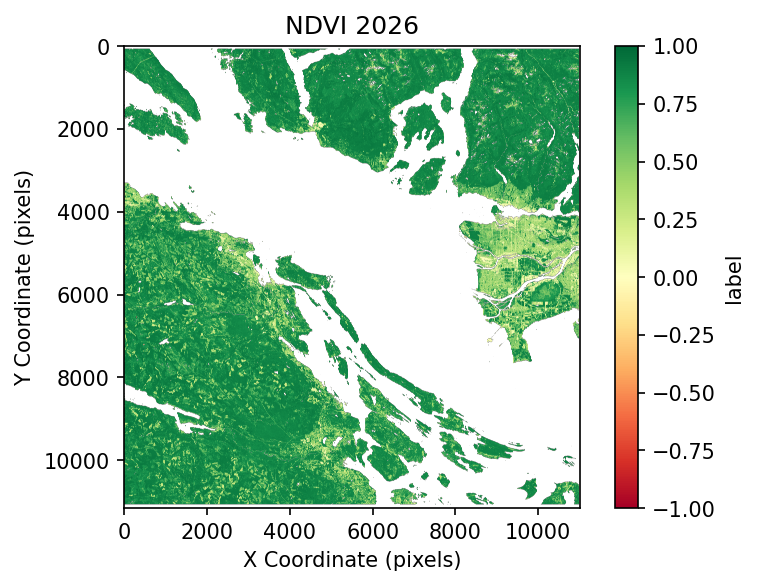

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_2026, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("NDVI 2026")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### 2024 Sentinel Data

In [19]:
MIN_COV = 0.90

def add_cov(img):
    cov = img.geometry().intersection(aoi, 1).area(1).divide(aoi.area(1))
    return img.set("aoi_cov", cov)

sentinel_2024 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2024-08-1","2024-08-31")
    .filter(ee.Filter.eq("MGRS_TILE", "10UDV"))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 30))
    #.map(add_cov)
    #.filter(ee.Filter.gte("aoi_cov", MIN_COV))      # keeps images covering at least 90% of the AOI
)

print("Matches:", sentinel_2024.size().getInfo())
print("Number of images:", sentinel_2024.size().getInfo())
print("Images:")
print(sentinel_2024.aggregate_array("system:index").getInfo())

Matches: 7
Number of images: 7
Images:
['20240805T191909_20240805T192816_T10UDV', '20240807T190911_20240807T191924_T10UDV', '20240810T191911_20240810T191959_T10UDV', '20240810T191911_20240810T193052_T10UDV', '20240815T191909_20240815T192805_T10UDV', '20240817T190911_20240817T191452_T10UDV', '20240830T191911_20240830T192023_T10UDV']


In [20]:
sentinel_2024_image = ee.Image(sentinel_2024.toList(sentinel_2024.size()).get(1))   # second image (index 1)
print(
    sentinel_2024_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE'
    ]).getInfo()
)

print(sentinel_2024_image.bandNames().getInfo())
print(sentinel_2024.size().getInfo())                  # must be 1 or more
img = ee.Image(sentinel_2024.first())
print(img.bandNames().getInfo())                       # must include B4, B8, SCL
print(aoi_utm.area(1).getInfo() / 1e6, "km²")          # should be a few hundred km²   

from IPython.display import Image, display

img = sentinel_2024_image            
url = img.select(["B4", "B3", "B2"]).getThumbURL({
    "region": aoi,                   
    "dimensions": 1000,              
    "min": 0, "max": 3000,           
    "format": "png",
})
display(Image(url=url))

{'CLOUDY_PIXEL_PERCENTAGE': 0.143168, 'DATATAKE_IDENTIFIER': 'GS2A_20240807T190911_047672_N05.11', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2A_MSIL2A_20240807T190911_N0511_R056_T10UDV_20240808T020449', 'system:index': '20240807T190911_20240807T191924_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
7
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


NameError: name 'aoi_utm' is not defined

In [ ]:
sentinel_bands_2024 = (
    sentinel_2024_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task_3 = ee.batch.Export.image.toDrive(
    image=sentinel_bands_2024,
    description="sentinel_l2a_20240807T190911_20240807T191924_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20240807T190911_20240807T191924_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_3.start()
print("Export started")

Export started


In [ ]:
print(task_3.status())

{'state': 'RUNNING', 'description': 'sentinel_l2a_20240807T190911_20240807T191924_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792099334042, 'update_timestamp_ms': 1792099580083, 'start_timestamp_ms': 1792099335443, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'batch_eecu_usage_seconds': 334.561, 'id': '7RX5GMAV5H37TTA5ZGR6HICS', 'name': 'projects/gis-project-510419/operations/7RX5GMAV5H37TTA5ZGR6HICS'}


In [ ]:
def coverage(img):
    return img.geometry().intersection(aoi, 1).area(1).divide(aoi.area(1)).getInfo()

print("2026:", coverage(sentinel_2026_image))
print("2024:", coverage(sentinel_2024_image))
print("orbits:", sentinel_2026_image.get("SENSING_ORBIT_NUMBER").getInfo(),
      sentinel_2024_image.get("SENSING_ORBIT_NUMBER").getInfo())

2026: 0.9912965480683368
2024: 0.8067440419876655
orbits: 56 99


In [23]:
sentinel_2024_data = r"Datasets\sentinel_l2a_20240807T190911_20240807T191924_T10UDV.tif"

with rasterio.open(sentinel_2024_data) as sentinel_2024_src:
    # Read each band from the Sentinel-2 multiband GeoTIFF
    sentinel_2024_B4_R = sentinel_2024_src.read(1)
    sentinel_2024_B8_NIR = sentinel_2024_src.read(2)
    sentinel_2024_SCL = sentinel_2024_src.read(3)

    # Dataset-level metadata
    sentinel_2024_B4_transform = sentinel_2024_src.transform
    sentinel_2024_B4_crs = sentinel_2024_src.crs
    sentinel_2024_B4_nodata = sentinel_2024_src.nodatavals[0]
    sentinel_2024_B4_shape = sentinel_2024_B4_R.shape

    print("CRS:", sentinel_2024_src.crs)
    print("Bounds:", sentinel_2024_src.bounds)
    print("Width:", sentinel_2024_src.width)
    print("Height:", sentinel_2024_src.height)
    print("Tags:", sentinel_2024_src.tags())
    print("Resolution:", sentinel_2024_src.res)
    print("NoData value:", sentinel_2024_src.nodata)
    print("Transform:", sentinel_2024_src.transform)
    print("Descriptions:", sentinel_2024_src.descriptions)

    '''
    sentinel_2024_bounds_4326 = transform_bounds(
            sentinel_2024_src.crs,
            "EPSG:4326",
            *sentinel_2024_src.bounds
        )
        print("WGS84 bounds:", sentinel_2024_bounds_4326)
    '''

    print("B4 min/max:", np.min(sentinel_2024_B4_R), np.max(sentinel_2024_B4_R))
    print("B8 min/max:", np.min(sentinel_2024_B8_NIR), np.max(sentinel_2024_B8_NIR))
    print("SCL min/max:", np.min(sentinel_2024_SCL), np.max(sentinel_2024_SCL))


CRS: EPSG:32610
Bounds: BoundingBox(left=399940.0, bottom=5388440.0, right=510170.0, top=5501780.0)
Width: 11023
Height: 11334
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399940.00|
| 0.00,-10.00, 5501780.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL', 'B2', 'B3')
B4 min/max: 0 17640
B8 min/max: 0 16536
SCL min/max: 0 11


In [ ]:
# Sentinel-2 L2A SCL masking + NDVI using the correct sentinel_2_* variable names
bad_classes_2024 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2024 = ~np.isin(sentinel_2024_SCL, bad_classes_2024)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2024_B4_R_mask = np.where(
    SCL_valid_mask_2024,
    sentinel_2024_B4_R,
    np.nan
)

sentinel_2024_B8_NIR_mask = np.where(
    SCL_valid_mask_2024,
    sentinel_2024_B8_NIR,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2024_B4_R_corrected = sentinel_2024_B4_R_mask * 0.0001
sentinel_2024_B8_NIR_corrected = sentinel_2024_B8_NIR_mask * 0.0001

denom_2024 = sentinel_2024_B4_R_corrected + sentinel_2024_B8_NIR_corrected
valid_reflectance_mask_2024 = (
    np.isfinite(sentinel_2024_B4_R_corrected)
    & np.isfinite(sentinel_2024_B8_NIR_corrected)
    & (sentinel_2024_B4_R_corrected >= 0)
    & (sentinel_2024_B8_NIR_corrected >= 0)
    & (denom_2024 > 1e-6)
)

# NDVI
ndvi_2024 = np.full(sentinel_2024_B4_shape, np.nan, dtype=np.float32)
np.divide(
    sentinel_2024_B8_NIR_corrected - sentinel_2024_B4_R_corrected,
    denom_2024,
    out=ndvi_2024,
    where=valid_reflectance_mask_2024
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

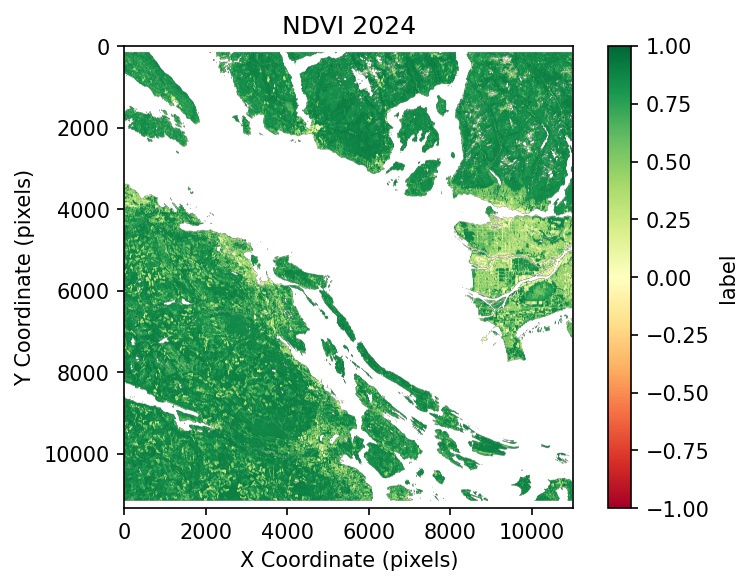

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_2024, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("NDVI 2024")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### 2025 Data

In [ ]:
sentinel_2025 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2025-08-1","2025-08-31")
    .filter(ee.Filter.eq("MGRS_TILE", "10UDV"))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 10))
    #.map(add_cov)
    #.filter(ee.Filter.gte("aoi_cov", MIN_COV))      # keeps images covering at least 90% of the AOI
)

print("Matches:", sentinel_2025.size().getInfo())
print("Number of images:", sentinel_2025.size().getInfo())
print("Images:")
print(sentinel_2025.aggregate_array("system:index").getInfo())

sentinel_2025_image = ee.Image(sentinel_2025.toList(sentinel_2025.size()).get(2))   # second image (index 1)
print(
    sentinel_2025_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE'
    ]).getInfo()
)

print(sentinel_2025_image.bandNames().getInfo())
print(sentinel_2025.size().getInfo())                  # must be 1 or more
img = ee.Image(sentinel_2025.first())
print(img.bandNames().getInfo())                       # must include B4, B8, SCL
print(aoi_utm.area(1).getInfo() / 1e6, "km²")          # should be a few hundred km²   

Matches: 5
Number of images: 5
Images:
['20250802T190931_20250802T191621_T10UDV', '20250810T191909_20250810T192442_T10UDV', '20250812T190931_20250812T191308_T10UDV', '20250822T190931_20250822T191956_T10UDV', '20250825T191931_20250825T192858_T10UDV']
{'CLOUDY_PIXEL_PERCENTAGE': 0.003149, 'DATATAKE_IDENTIFIER': 'GS2C_20250812T190931_004888_N05.11', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2C_MSIL2A_20250812T190931_N0511_R056_T10UDV_20250813T002416', 'system:index': '20250812T190931_20250812T191308_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
5
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
968.26711

In [ ]:
from IPython.display import Image, display

img = sentinel_2025_image            
url = img.select(["B4", "B3", "B2"]).getThumbURL({
    "region": aoi,                   
    "dimensions": 1000,              
    "min": 0, "max": 3000,           
    "format": "png",
})
display(Image(url=url))

In [ ]:
for img in (sentinel_2024_image, sentinel_2025_image):
    print(img.get("PRODUCT_ID").getInfo(),
          img.get("MEAN_SOLAR_ZENITH_ANGLE").getInfo(),
          img.get("MEAN_SOLAR_AZIMUTH_ANGLE").getInfo())

S2A_MSIL2A_20240906T190921_N0511_R056_T10UDV_20240907T023150 44.4866888185703 161.538596624214
S2A_MSIL2A_20250923T191831_N0511_R056_T10UDV_20250923T220413 50.5236377711311 165.225880648168


In [ ]:
sentinel_2025_bands = (
    sentinel_2025_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task_4 = ee.batch.Export.image.toDrive(
    image=sentinel_2025_bands,
    description="sentinel_l2a_20250812T190931_20250812T191308_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20250812T190931_20250812T191308_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_4.start()
print("Export started")

Export started


In [ ]:
print(task_4.status())

{'state': 'COMPLETED', 'description': 'sentinel_l2a_20250812T190931_20250812T191308_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792100223327, 'update_timestamp_ms': 1792100733196, 'start_timestamp_ms': 1792100225397, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/16PMye91hB5cePcHjvv1Tr8_qE50-lc8r'], 'attempt': 1, 'batch_eecu_usage_seconds': 524.5396728515625, 'id': 'YL6JSYUW7PTOKNCAUCUB7JEU', 'name': 'projects/gis-project-510419/operations/YL6JSYUW7PTOKNCAUCUB7JEU'}


In [ ]:
sentinel_2025_data = r"Datasets\sentinel_l2a_20250812T190931_20250812T191308_T10UDV.tif"

with rasterio.open(sentinel_2025_data) as sentinel_2025_src:
    # Read each band from the Sentinel-2 multiband GeoTIFF
    band_index = {
        name: i + 1
        for i, name in enumerate(sentinel_2025_src.descriptions)
    }

    sentinel_2025_B4_R = sentinel_2025_src.read(band_index["B4"])
    sentinel_2025_B8_NIR = sentinel_2025_src.read(band_index["B8"])
    sentinel_2025_SCL = sentinel_2025_src.read(band_index["SCL"])
    sentinel_2025_B2 = sentinel_2025_src.read(band_index["B2"])
    sentinel_2025_B3 = sentinel_2025_src.read(band_index["B3"])

    # Dataset-level metadata
    sentinel_2025_B4_transform = sentinel_2025_src.transform
    sentinel_2025_B4_crs = sentinel_2025_src.crs
    sentinel_2025_B4_nodata = sentinel_2025_src.nodatavals[0]
    sentinel_2025_B4_shape = sentinel_2025_B4_R.shape

    print("CRS:", sentinel_2025_src.crs)
    print("Bounds:", sentinel_2025_src.bounds)
    print("Width:", sentinel_2025_src.width)
    print("Height:", sentinel_2025_src.height)
    print("Tags:", sentinel_2025_src.tags())
    print("Resolution:", sentinel_2025_src.res)
    print("NoData value:", sentinel_2025_src.nodata)
    print("Transform:", sentinel_2025_src.transform)
    print("Descriptions:", sentinel_2025_src.descriptions)

    '''
    sentinel_2025_bounds_4326 = transform_bounds(
        sentinel_2025_src.crs,
        "EPSG:4326",
        *sentinel_2025_src.bounds
    )
    print("WGS84 bounds:", sentinel_2025_bounds_4326)
    '''

    print("B4 min/max:", np.min(sentinel_2025_B4_R), np.max(sentinel_2025_B4_R))
    print("B8 min/max:", np.min(sentinel_2025_B8_NIR), np.max(sentinel_2025_B8_NIR))
    print("SCL min/max:", np.min(sentinel_2025_SCL), np.max(sentinel_2025_SCL))

print("Total SCL pixels:", sentinel_2025_SCL.size)
print("Total SCL zeros:", np.count_nonzero(sentinel_2025_SCL == 0))

CRS: EPSG:32610
Bounds: BoundingBox(left=399940.0, bottom=5388440.0, right=510170.0, top=5501780.0)
Width: 11023
Height: 11334
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399940.00|
| 0.00,-10.00, 5501780.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL', 'B2', 'B3')
B4 min/max: 0 16328
B8 min/max: 0 15720
SCL min/max: 0 11
Total SCL pixels: 124934682
Total SCL zeros: 4374282


In [ ]:
# Sentinel-2 L2A SCL masking + NDVI
bad_classes_2025 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2025 = ~np.isin(sentinel_2025_SCL, bad_classes_2025)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2025_B4_R_mask = np.where(
    SCL_valid_mask_2025,
    sentinel_2025_B4_R,
    np.nan
)

sentinel_2025_B8_NIR_mask = np.where(
    SCL_valid_mask_2025,
    sentinel_2025_B8_NIR,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2025_B4_R_corrected = sentinel_2025_B4_R_mask * 0.0001
sentinel_2025_B8_NIR_corrected = sentinel_2025_B8_NIR_mask * 0.0001

denom_2025 = sentinel_2025_B4_R_corrected + sentinel_2025_B8_NIR_corrected
valid_reflectance_mask_2025 = (
    np.isfinite(sentinel_2025_B4_R_corrected)
    & np.isfinite(sentinel_2025_B8_NIR_corrected)
    & (sentinel_2025_B4_R_corrected >= 0)
    & (sentinel_2025_B8_NIR_corrected >= 0)
    & (denom_2025 > 1e-6)
)

# NDVI
ndvi_2025 = np.full(sentinel_2025_B4_shape, np.nan, dtype=np.float32)
np.divide(
    sentinel_2025_B8_NIR_corrected - sentinel_2025_B4_R_corrected,
    denom_2025,
    out=ndvi_2025,
    where=valid_reflectance_mask_2025
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

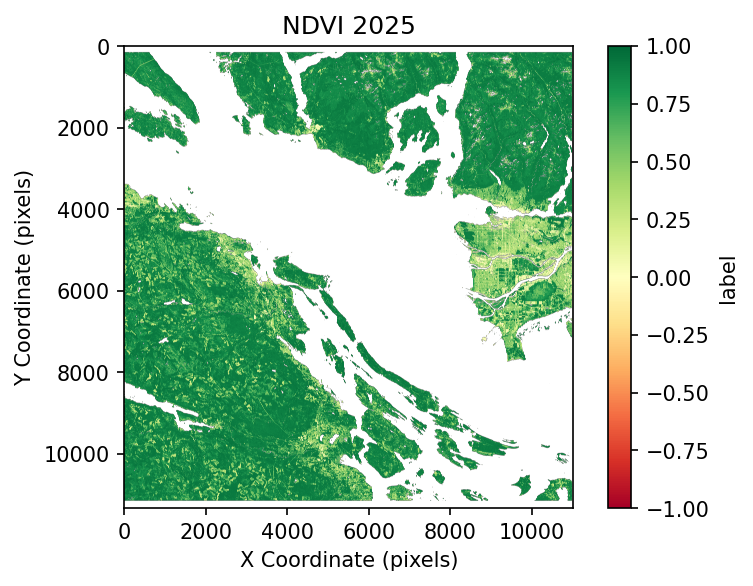

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_2025, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("NDVI 2025")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

## DEM Reproject, Statistics, and Slope

In [ ]:
from rasterio.warp import reproject, Resampling

elevation_reproject = np.empty(sentinel_2026_B4_shape, dtype=np.float32)

reproject(
    source=elevation_valid,
    destination=elevation_reproject,
    src_transform=elevation_transform,
    src_crs=elevation_crs,
    dst_transform=sentinel_2026_B4_transform,
    dst_crs=sentinel_2026_B4_crs,
    dst_nodata=np.nan,
    shape=sentinel_2026_B4_shape,
    resampling=Resampling.nearest
)

print(elevation_reproject.shape)

(11334, 11023)


In [ ]:
# Crop the reprojected DEM 
valid_DEM = np.isfinite(elevation_reproject)
rows, cols = np.where(valid_DEM)

if rows.size == 0:
    raise ValueError("elevation_reproject contains no finite data")

row0, row1 = rows.min(), rows.max() + 1  
col0, col1 = cols.min(), cols.max() + 1
elevation_crop = elevation_reproject[row0:row1, col0:col1]

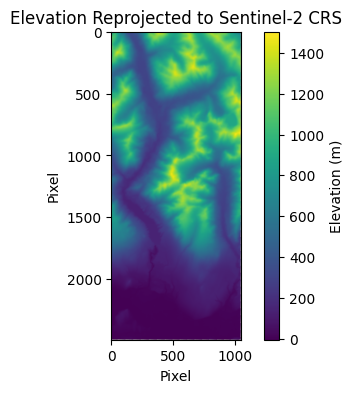

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(elevation_crop, cmap="viridis")
cbar = fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title("Elevation Reprojected to Sentinel-2 CRS")
ax.set_xlabel("Pixel")
ax.set_ylabel("Pixel")
plt.show()

### GDAL Slope

In [ ]:
from osgeo import gdal
from affine import Affine

print(gdal.__version__)

3.13.3


In [ ]:
# Create a GDAL in-memory dataset for the cropped DEM
dem_array = elevation_crop.astype(np.float32)
rows, cols = dem_array.shape

print("Rows:", rows)
print("Columns:", cols)

from osgeo import gdal

driver = gdal.GetDriverByName("MEM")
ds = driver.Create(
    "",
    cols,
    rows,
    1,
    gdal.GDT_Float32
)

# Translate the GDAL geotransform to match the cropped DEM's position in the original Sentinel-2 grid
crop_transform = sentinel_2026_B4_transform * Affine.translation(col0, row0)
ds.SetGeoTransform(crop_transform.to_gdal())
ds.SetProjection(sentinel_2026_B4_crs.to_wkt())

band = ds.GetRasterBand(1)
band.WriteArray(dem_array)
band.SetNoDataValue(np.nan)

slope_ds = gdal.DEMProcessing(
    "",
    ds,
    "slope",
    format="MEM",
    slopeFormat="degree",
    alg="Horn"
)

slope_band = slope_ds.GetRasterBand(1)
slope_gdal_array = slope_band.ReadAsArray()
slope_gdal_array = np.where(
    slope_gdal_array == -9999,
    np.nan,
    slope_gdal_array
)

Rows: 2490
Columns: 1046


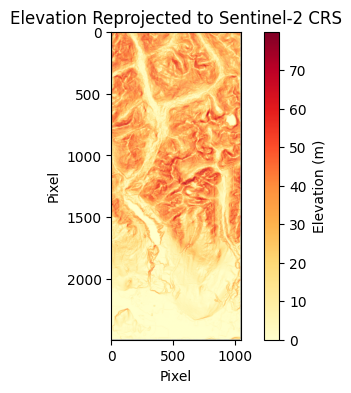

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(slope_gdal_array, cmap="YlOrRd")
cbar = fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title("Elevation Reprojected to Sentinel-2 CRS")
ax.set_xlabel("Pixel")
ax.set_ylabel("Pixel")
plt.show()

Elevation (Max, Min, Std, Mean, Med, Skew): [np.float32(1503.917), np.float32(-5.463), np.float32(391.065), np.float32(523.399), np.float32(481.819), np.float32(0.269)]
Slope (Max, Min, Std, Mean, Med, Skew): [np.float32(79.927), np.float32(0.0), np.float32(16.738), np.float32(19.663), np.float32(16.143), np.float32(0.618)]


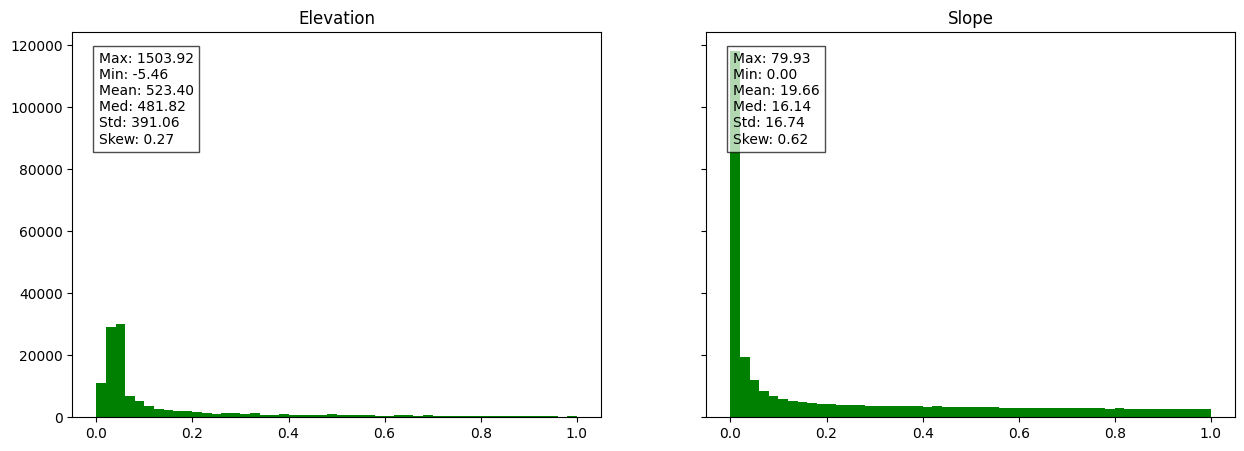

In [ ]:
from scipy.stats import skew

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True, dpi = 100)
data_labels = ["Elevation", "Slope"]
datasets = [elevation_crop, slope_gdal_array]

for i, (data_labels, data) in enumerate(zip(data_labels, datasets)):
    # Clean data (removes missing values)
    v = data.ravel()[np.isfinite(data.ravel())]
    
    # Calculate stats
    stats = [v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v)]
    
    # Print to console
    print(f"{data_labels} (Max, Min, Std, Mean, Med, Skew):", [round(x, 3) for x in stats])
    
    # Plot histogram
    axes[i].hist(v, bins=50, color="green", range=(0, 1))
    axes[i].set_title(f"{data_labels}")
    
    # Label stats text on the plot top-left
    text = f"Max: {stats[0]:.2f}\nMin: {stats[1]:.2f}\nMean: {stats[3]:.2f}\nMed: {stats[4]:.2f}\nStd: {stats[2]:.2f}\nSkew: {stats[5]:.2f}"
    axes[i].text(0.05, 0.95, text, transform=axes[i].transAxes, va='top', bbox=dict(facecolor='white', alpha=0.7))

plt.show()

## Temporal NDVI Analysis

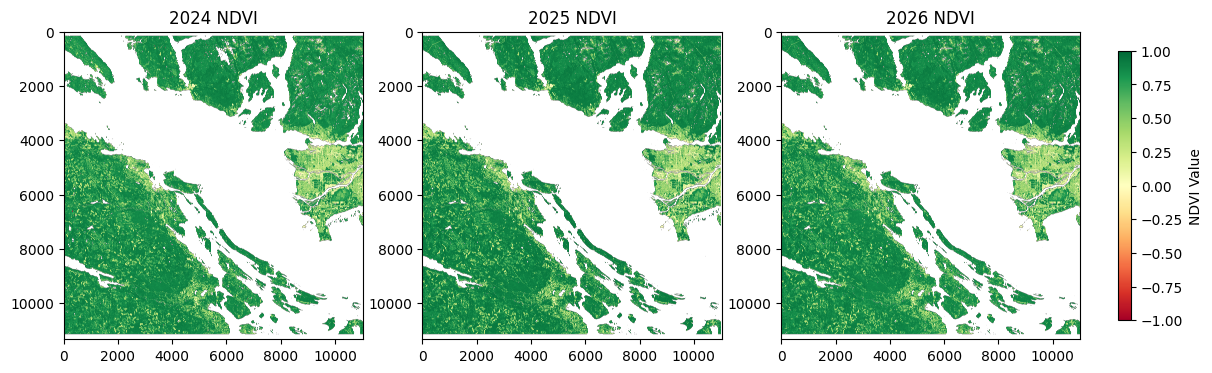

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=100)
cmap = "RdYlGn"

im = axes[0].imshow(ndvi_2024, cmap=cmap, vmin=-1, vmax=1)
axes[0].set_title("2024 NDVI")
axes[1].imshow(ndvi_2025, cmap=cmap, vmin=-1, vmax=1)
axes[1].set_title("2025 NDVI")
axes[2].imshow(ndvi_2026, cmap=cmap, vmin=-1, vmax=1)
axes[2].set_title("2026 NDVI")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")
plt.show()

In [ ]:
import pandas as pd

# Change these to choose the window
start_row = 200
start_col = 200
row_end = 350
col_end = 350

ndvi_2024_table = pd.DataFrame(ndvi_2024[start_row:row_end, start_col:col_end])
ndvi_2025_table = pd.DataFrame(ndvi_2025[start_row:row_end, start_col:col_end])
ndvi_2026_table = pd.DataFrame(ndvi_2026[start_row:row_end, start_col:col_end])

display(ndvi_2024_table)
display(ndvi_2025_table)
display(ndvi_2026_table)

,0,1,2,3,4,5,6,7,8,9,...,140,141,142,143,144,145,146,147,148,149
0,0.824482,0.856203,0.830379,0.751438,0.417358,0.234752,0.528558,0.808511,0.791183,0.797012,...,0.808627,0.778862,0.705680,0.718076,0.801980,0.823634,0.833586,0.792359,0.794665,0.826745
1,0.847780,0.859703,0.851165,0.805507,0.655901,0.284363,0.258278,0.460512,0.727670,0.795691,...,0.772765,0.756559,0.784240,0.803691,0.785533,0.821032,0.848706,0.805545,0.809449,0.798635
2,0.836225,0.842488,0.841176,0.798064,0.732333,0.656250,0.439024,0.525180,0.764036,0.816989,...,0.762272,0.761302,0.778177,0.784007,0.773424,0.805959,0.837875,0.813733,0.807823,0.788799
3,0.864737,0.845550,0.863329,0.867801,0.847648,0.843611,0.837337,0.870092,0.872187,0.860974,...,0.764752,0.748333,0.755158,0.751657,0.777166,0.769593,0.781363,0.782271,0.774167,0.774052
4,0.873266,0.875000,0.875648,0.868629,0.874060,0.862020,0.873042,0.868198,0.879859,0.873389,...,0.757053,0.738891,0.753982,0.730249,0.751903,0.755333,0.791340,0.786408,0.746626,0.745978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,0.853964,0.864640,0.855740,0.850953,0.847086,0.850768,0.853056,0.829186,0.843953,0.847282,...,0.819730,0.808992,0.830800,0.818634,0.830425,0.849503,0.850629,0.848869,0.822768,0.785349
146,0.830508,0.854880,0.853659,0.849893,0.852379,0.847875,0.837293,0.819418,0.832465,0.826120,...,0.797015,0.812564,0.810620,0.792332,0.819763,0.836850,0.851409,0.850894,0.815303,0.802708
147,0.830174,0.849523,0.820968,0.814800,0.839450,0.839588,0.839357,0.832278,0.861579,0.851226,...,0.786088,0.762712,0.780664,0.744646,0.776545,0.830248,0.845762,0.814921,0.813358,0.803175
148,0.824509,0.844088,0.783825,0.735549,0.762689,0.813715,0.848214,0.857442,0.836735,0.853529,...,0.770414,0.708378,0.749821,0.725767,0.764706,0.811646,0.812794,0.822155,0.820416,0.792717


,0,1,2,3,4,5,6,7,8,9,...,140,141,142,143,144,145,146,147,148,149
0,0.863135,0.890176,0.870322,0.842105,0.603185,0.237564,0.456382,0.718068,0.800919,0.825296,...,0.819992,0.805520,0.787976,0.804857,0.821056,0.861039,0.872183,0.833678,0.828814,0.864562
1,0.872291,0.883967,0.886387,0.856655,0.769457,0.404678,0.357482,0.519664,0.752308,0.852268,...,0.802490,0.811058,0.839246,0.838683,0.816296,0.846051,0.876543,0.866761,0.848753,0.838573
2,0.880665,0.877256,0.888493,0.884669,0.854015,0.798061,0.820576,0.816254,0.857197,0.871688,...,0.797915,0.791610,0.808292,0.813494,0.812585,0.831715,0.854101,0.844576,0.835535,0.809992
3,0.896490,0.909756,0.909280,0.896433,0.881979,0.870187,0.882728,0.905905,0.905904,0.900055,...,0.790698,0.775877,0.803815,0.788520,0.797023,0.791871,0.826747,0.821510,0.786517,0.791925
4,0.906401,0.915433,0.910988,0.910761,0.897898,0.886000,0.888646,0.898305,0.909484,0.916296,...,0.788307,0.774081,0.804603,0.763806,0.788574,0.812281,0.827966,0.819936,0.774732,0.749684
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,0.892522,0.902605,0.892059,0.892197,0.888493,0.897674,0.898692,0.866391,0.878273,0.866293,...,0.863484,0.866299,0.864572,0.861044,0.848921,0.869318,0.877623,0.882734,0.866508,0.843866
146,0.871069,0.890796,0.885123,0.875499,0.863946,0.879556,0.878039,0.862069,0.897611,0.887677,...,0.846396,0.834927,0.839539,0.839768,0.846855,0.872431,0.873525,0.874733,0.868895,0.858413
147,0.862972,0.880177,0.862069,0.846044,0.866858,0.879853,0.881475,0.898556,0.899423,0.902138,...,0.814958,0.771202,0.808527,0.761483,0.799119,0.868603,0.865955,0.877887,0.880342,0.852662
148,0.869942,0.867735,0.773739,0.668239,0.715283,0.792255,0.871804,0.898257,0.884966,0.904605,...,0.818784,0.748031,0.731183,0.754917,0.822119,0.861213,0.836854,0.859601,0.854987,0.831875


,0,1,2,3,4,5,6,7,8,9,...,140,141,142,143,144,145,146,147,148,149
0,0.863183,0.891731,0.881238,0.850473,0.580429,0.289984,0.501850,0.779709,0.822703,0.832380,...,0.856156,0.833600,0.753324,0.804749,0.833575,0.864295,0.875537,0.840918,0.856796,0.869892
1,0.872889,0.885210,0.893805,0.886299,0.780420,0.390578,0.363757,0.530210,0.757267,0.847273,...,0.812024,0.806897,0.855791,0.854767,0.819780,0.860311,0.866452,0.852369,0.849226,0.855349
2,0.882690,0.877818,0.877799,0.884633,0.848661,0.792839,0.796009,0.752201,0.859392,0.888265,...,0.812898,0.808028,0.820604,0.827859,0.816586,0.850579,0.857980,0.865203,0.850346,0.833333
3,0.901136,0.897543,0.900504,0.905097,0.887309,0.873466,0.878154,0.899966,0.905409,0.902476,...,0.817054,0.784946,0.788235,0.803030,0.818992,0.823602,0.820690,0.829528,0.811699,0.811583
4,0.900840,0.911721,0.904786,0.907036,0.895814,0.893147,0.890418,0.896960,0.905272,0.913478,...,0.829787,0.787533,0.797685,0.784472,0.793714,0.805333,0.820534,0.837627,0.801847,0.782591
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,0.888097,0.889053,0.890620,0.886806,0.901161,0.902906,0.894669,0.866624,0.875335,0.871139,...,0.873518,0.868667,0.857192,0.844009,0.847619,0.865701,0.870114,0.890482,0.859530,0.862536
146,0.870943,0.889226,0.886819,0.879647,0.889208,0.885585,0.883962,0.866828,0.878226,0.885846,...,0.855404,0.837094,0.857497,0.857955,0.874239,0.872429,0.875941,0.888550,0.871489,0.878843
147,0.867619,0.879073,0.864311,0.866202,0.877107,0.871658,0.877419,0.881030,0.890753,0.898156,...,0.854793,0.799013,0.786787,0.765592,0.801060,0.854987,0.868103,0.884830,0.875815,0.863697
148,0.862474,0.886749,0.809889,0.718372,0.784575,0.828283,0.886541,0.889997,0.891220,0.914680,...,0.847526,0.776351,0.752680,0.790469,0.821467,0.863486,0.842475,0.848347,0.867084,0.855124


In [ ]:
ndvi_2024_crop = ndvi_2024[row0:row1, col0:col1]
ndvi_2025_crop = ndvi_2025[row0:row1, col0:col1]
ndvi_2026_crop = ndvi_2026[row0:row1, col0:col1]

print(ndvi_2026_crop.shape)
print(elevation_crop.shape)

(2490, 1046)
(2490, 1046)


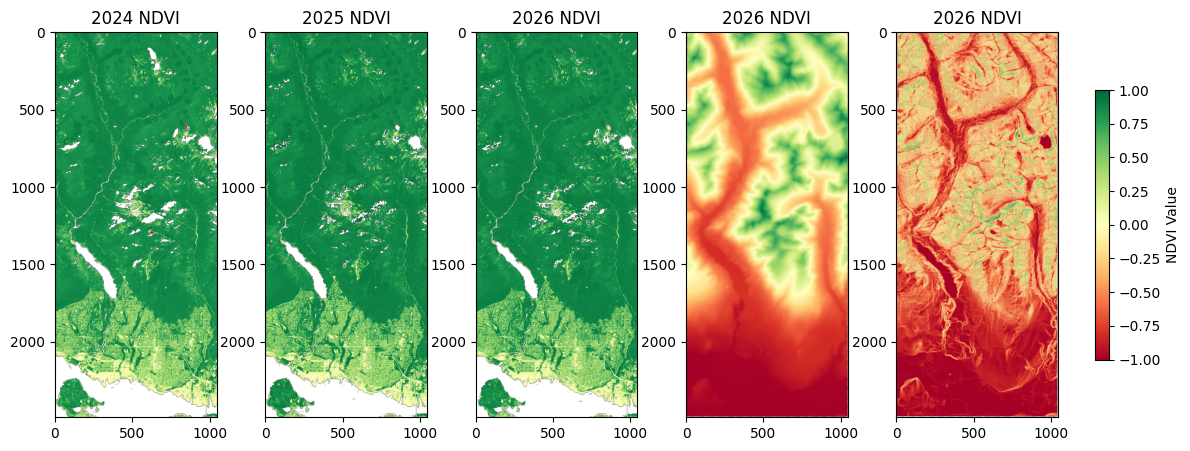

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5), dpi=100)
cmap = "RdYlGn"

im = axes[0].imshow(ndvi_2024_crop, cmap=cmap, vmin=-1, vmax=1)
axes[0].set_title("2024 NDVI")
axes[1].imshow(ndvi_2025_crop, cmap=cmap, vmin=-1, vmax=1)
axes[1].set_title("2025 NDVI")
axes[2].imshow(ndvi_2026_crop, cmap=cmap, vmin=-1, vmax=1)
axes[2].set_title("2026 NDVI")

axes[3].imshow(elevation_crop, cmap=cmap)
axes[3].set_title("2026 NDVI")
axes[4].imshow(slope_gdal_array, cmap=cmap)
axes[4].set_title("2026 NDVI")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")
plt.show()

2024 (Count [0, 1], Count [-1, 0], Max, Min, Std, Mean, Med, Skew): [np.int64(2323233), np.int64(9365), np.float32(1.0), np.float32(-1.0), np.float32(0.209), np.float32(0.745), np.float32(0.831), np.float32(-2.124)]
2025 (Count [0, 1], Count [-1, 0], Max, Min, Std, Mean, Med, Skew): [np.int64(2351824), np.int64(7756), np.float32(1.0), np.float32(-1.0), np.float32(0.211), np.float32(0.774), np.float32(0.863), np.float32(-2.053)]
2026 (Count [0, 1], Count [-1, 0], Max, Min, Std, Mean, Med, Skew): [np.int64(2350916), np.int64(5306), np.float32(1.0), np.float32(-1.0), np.float32(0.206), np.float32(0.775), np.float32(0.862), np.float32(-2.113)]


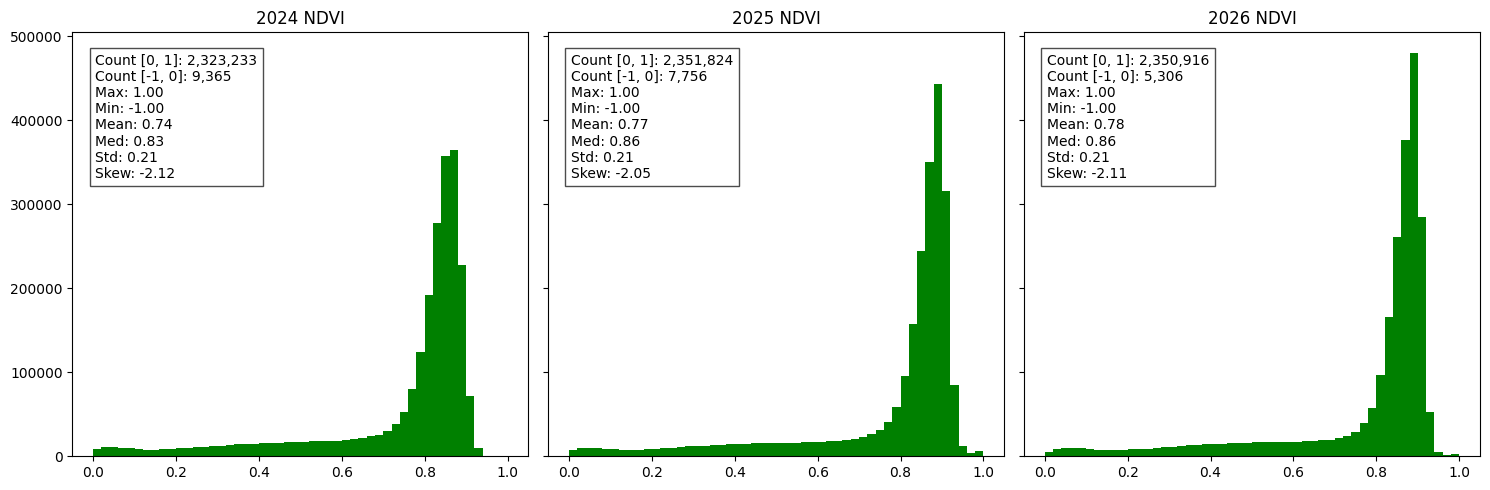

In [ ]:
from scipy.stats import skew

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, dpi=100)
years = ["2024", "2025", "2026"]
datasets = [ndvi_2024_crop, ndvi_2025_crop, ndvi_2026_crop]

for i, (year, data) in enumerate(zip(years, datasets)):
    # Exclude missing values
    v = data.ravel()[np.isfinite(data.ravel())]

    count_0_to_1 = np.count_nonzero((v >= 0) & (v <= 1))
    count_neg1_to_0 = np.count_nonzero((v >= -1) & (v <= 0))

    # Calculate stats
    stats = [
        count_0_to_1,
        count_neg1_to_0,
        v.max(),
        v.min(),
        v.std(),
        v.mean(),
        np.median(v),
        skew(v)
    ]

    # Print counts and stats
    print(
        f"{year} (Count [0, 1], Count [-1, 0], Max, Min, Std, Mean, Med, Skew):",
        [round(x, 3) for x in stats]
    )

    # Plot histogram
    axes[i].hist(v, bins=50, color="green", range=(0, 1))
    axes[i].set_title(f"{year} NDVI")

    # Keep the existing plot annotation; counts are printed above, not plotted
    text = (
    f"Count [0, 1]: {stats[0]:,}\n"
    f"Count [-1, 0]: {stats[1]:,}\n"
    f"Max: {stats[2]:.2f}\nMin: {stats[3]:.2f}\n"
    f"Mean: {stats[5]:.2f}\nMed: {stats[6]:.2f}\n"
    f"Std: {stats[4]:.2f}\nSkew: {stats[7]:.2f}"
)   
    axes[i].text(
        0.05, 0.95, text,
        transform=axes[i].transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.7)
    )

plt.tight_layout()
plt.show()

C:\Users\matil\AppData\Local\Temp\ipykernel_9828\2594329526.py:10: UserWarning: Adding colorbar to a different Figure <Figure size 1600x500 with 4 Axes> than <Figure size 1000x500 with 4 Axes> which fig.colorbar is called on.
  cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)


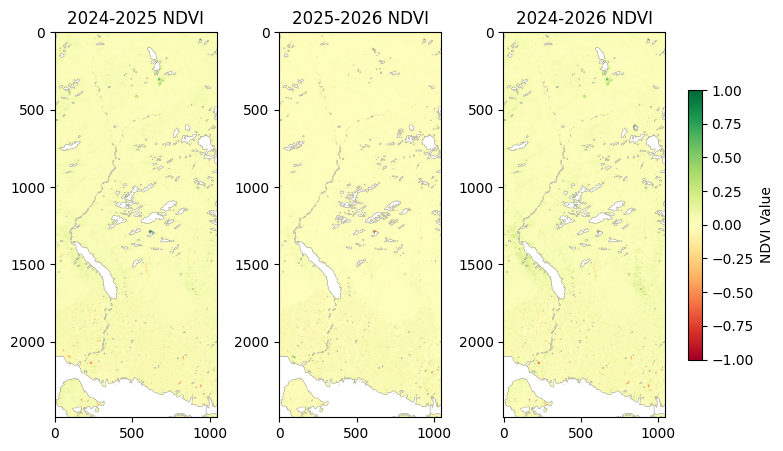

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5), dpi=100)

axes[0].imshow(ndvi_2025_crop-ndvi_2024_crop, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title("2024-2025 NDVI")
axes[1].imshow(ndvi_2026_crop-ndvi_2025_crop, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("2025-2026 NDVI")
axes[2].imshow(ndvi_2026_crop-ndvi_2024_crop, cmap="RdYlGn", vmin=-1, vmax=1)
axes[2].set_title("2024-2026 NDVI")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")
plt.show()

In [ ]:
# COUNTS Before After

2024-2025 (Max, Min, Std, Mean, Med, Skew): [np.float32(2.0), np.float32(-0.869), np.float32(0.049), np.float32(0.027), np.float32(0.025), np.float32(4.751)]
2025-2026 (Max, Min, Std, Mean, Med, Skew): [np.float32(1.089), np.float32(-2.0), np.float32(0.039), np.float32(0.002), np.float32(-0.0), np.float32(-2.944)]
2024-2026 (Max, Min, Std, Mean, Med, Skew): [np.float32(2.0), np.float32(-1.157), np.float32(0.047), np.float32(0.029), np.float32(0.025), np.float32(1.636)]


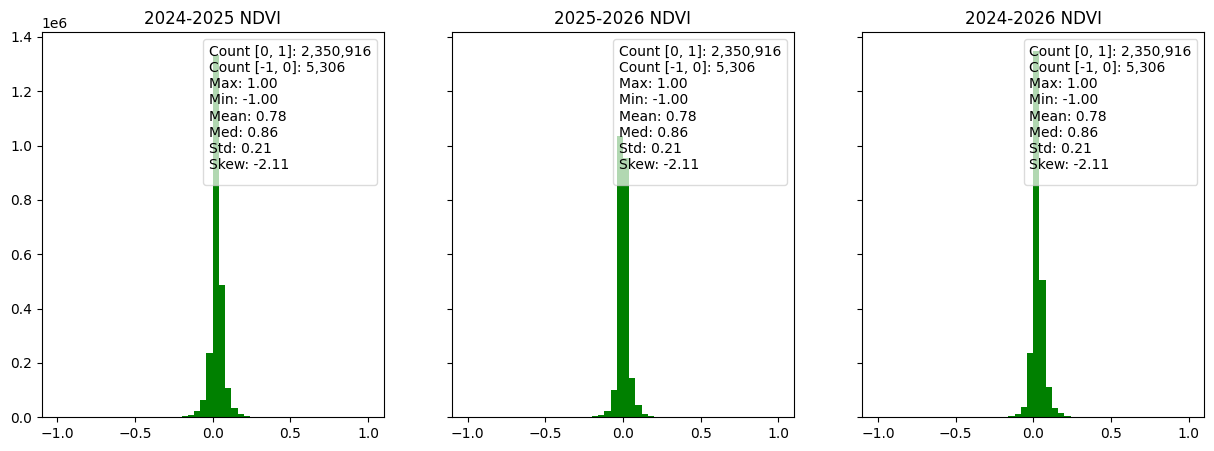

In [ ]:
from scipy.stats import skew

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, dpi = 100)
years = ["2024-2025", "2025-2026", "2024-2026"]
datasets = [ndvi_2025_crop-ndvi_2024_crop, ndvi_2026_crop-ndvi_2025_crop, ndvi_2026_crop-ndvi_2024_crop]

for i, (year, data) in enumerate(zip(years, datasets)):
    # Clean data (removes missing values)
    v = data.ravel()[np.isfinite(data.ravel())]
    
    # Calculate stats
    stats = [v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v)]
    
    # Print to console
    print(f"{year} (Max, Min, Std, Mean, Med, Skew):", [round(x, 3) for x in stats])
    
    # Plot histogram
    axes[i].hist(v, bins=50, color="green", range=(-1, 1))
    axes[i].set_title(f"{year} NDVI")

    axes[i].legend(
    [], [],
    title=text,
    loc="best",
    framealpha=0.7
)
    
plt.show()


## Statistical Analysis, Kmeans, and Random Forest

In [ ]:
valid_ndvi_2024_mask = np.isfinite(ndvi_2024_crop)
valid_ndvi_2024 = ndvi_2024_crop[valid_ndvi_2024_mask]

valid_ndvi_2025_mask = np.isfinite(ndvi_2025_crop)
valid_ndvi_2025 = ndvi_2025_crop[valid_ndvi_2025_mask]

valid_ndvi_2026_mask = np.isfinite(ndvi_2026_crop)
valid_ndvi_2026 = ndvi_2026_crop[valid_ndvi_2026_mask]


reshaped_ndvi_2024 = valid_ndvi_2024.reshape(-1, 1)
reshaped_ndvi_2025 = valid_ndvi_2025.reshape(-1, 1)
reshaped_ndvi_2026 = valid_ndvi_2026.reshape(-1, 1)

print("NaN count:", np.isnan(valid_ndvi_2026).sum())
print("NaN count:", np.isnan(valid_ndvi_2024).sum())
print("NaN count:", np.isnan(valid_ndvi_2025).sum())

ndvi_all = np.concatenate([reshaped_ndvi_2024, reshaped_ndvi_2025, reshaped_ndvi_2026])

from sklearn.cluster import KMeans

model = KMeans(n_clusters=4, random_state=42, n_init="auto")
model.fit(ndvi_all)

NaN count: 0
NaN count: 0
NaN count: 0


,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [ ]:
cluster_map_2024 = np.full(ndvi_2024_crop.shape, np.nan)
cluster_map_2025 = np.full(ndvi_2025_crop.shape, np.nan)
cluster_map_2026 = np.full(ndvi_2026_crop.shape, np.nan)

cluster_map_2024[valid_ndvi_2024_mask] = model.predict(reshaped_ndvi_2024)
cluster_map_2025[valid_ndvi_2025_mask] = model.predict(reshaped_ndvi_2025)
cluster_map_2026[valid_ndvi_2026_mask] = model.predict(reshaped_ndvi_2026)

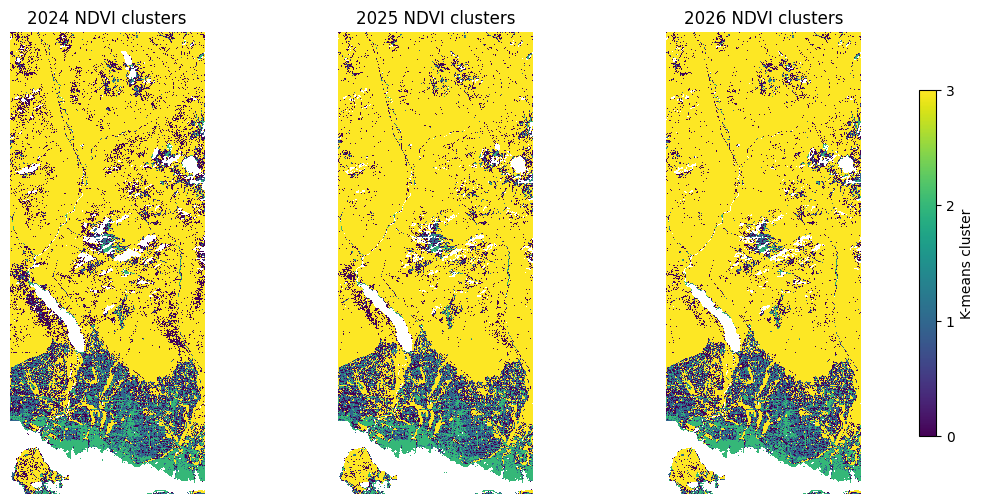

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=100)

for ax, (year, cluster_map) in zip(
    axes,
    [
        ("2024", cluster_map_2024),
        ("2025", cluster_map_2025),
        ("2026", cluster_map_2026)
    ]
):
    im = ax.imshow(
        cluster_map,
        cmap="viridis",
        vmin=0,
        vmax=model.n_clusters - 1,
        interpolation="nearest"
    )
    ax.set_title(f"{year} NDVI clusters")
    ax.axis("off")

fig.colorbar(
    im, ax=axes, ticks=range(model.n_clusters),
    label="K-means cluster", shrink=0.75
)

plt.show()

### Zenith/shadow/sun angle?

## Dynamic World V1

In [26]:
dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2026-08-1", "2026-08-1")
    .filterBounds(aoi)
)

print("Number of images:", dw.size().getInfo())
print("Images:")
print(dw.aggregate_array("system:index").getInfo())

NameError: name 'aoi' is not defined

In [25]:
dw_image = dw.filter(
    ee.Filter.eq(
        "system:index",
        "20260918T191831_20260918T191827_T10UDV"
    )
).first()

print(dw_image.getInfo()["id"])
print(dw_image.bandNames().getInfo())

NameError: name 'dw' is not defined

In [ ]:
dw_label = dw_image.select("label")

task = ee.batch.Export.image.toDrive(
    image=dw_label,
    description="dynamic_world_20260918_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="dynamic_world_20260918_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task.start()

print("Export started")

Export started


In [ ]:
print(task.status())

In [ ]:
dynamic_world_tif_path = r"Dynamic_World_tif\dynamic_world_20260918_T10UDV.tif"
src = rasterio.open(dynamic_world_tif_path)

# Raster Metadata
with rasterio.open(dynamic_world_tif_path) as dw_src:
    print("CRS:", dw_src.crs)
    print("Bounds:", dw_src.bounds)
    print("Width:", dw_src.width)
    print("Height:", dw_src.height)
    print(dw_src.tags())
    #print(dw_src.crs.to_wkt())
    print("Resolution:", dw_src.res)
    print("NoData value:", dw_src.nodata)
    print("Transform:", dw_src.transform)

    dw_bounds_4326 = transform_bounds(
        dw_src.crs,
        "EPSG:4326",
        *dw_src.bounds
    )

    print("WGS84 bounds:", dw_bounds_4326)

    dw_data = dw_src.read(1)

CRS: EPSG:32610
Bounds: BoundingBox(left=399950.0, bottom=5389330.0, right=509960.0, top=5500900.0)
Width: 11001
Height: 11157
{'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
WGS84 bounds: (-124.38609081028761, 48.649014843483585, -122.86199326082338, 49.66063805144947)


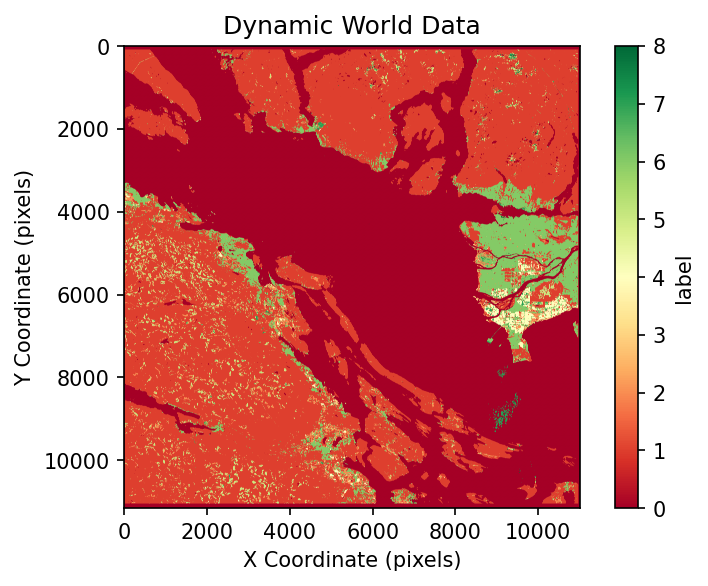

In [ ]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(dw_data, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("Dynamic World Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

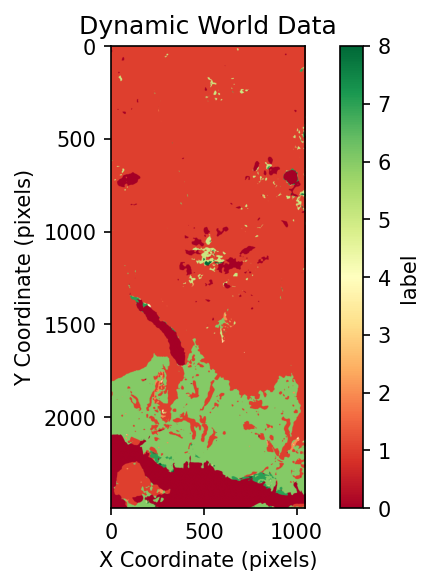

In [ ]:
dw_crop = dw_data[row0:row1, col0:col1]

# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(dw_crop, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("Dynamic World Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

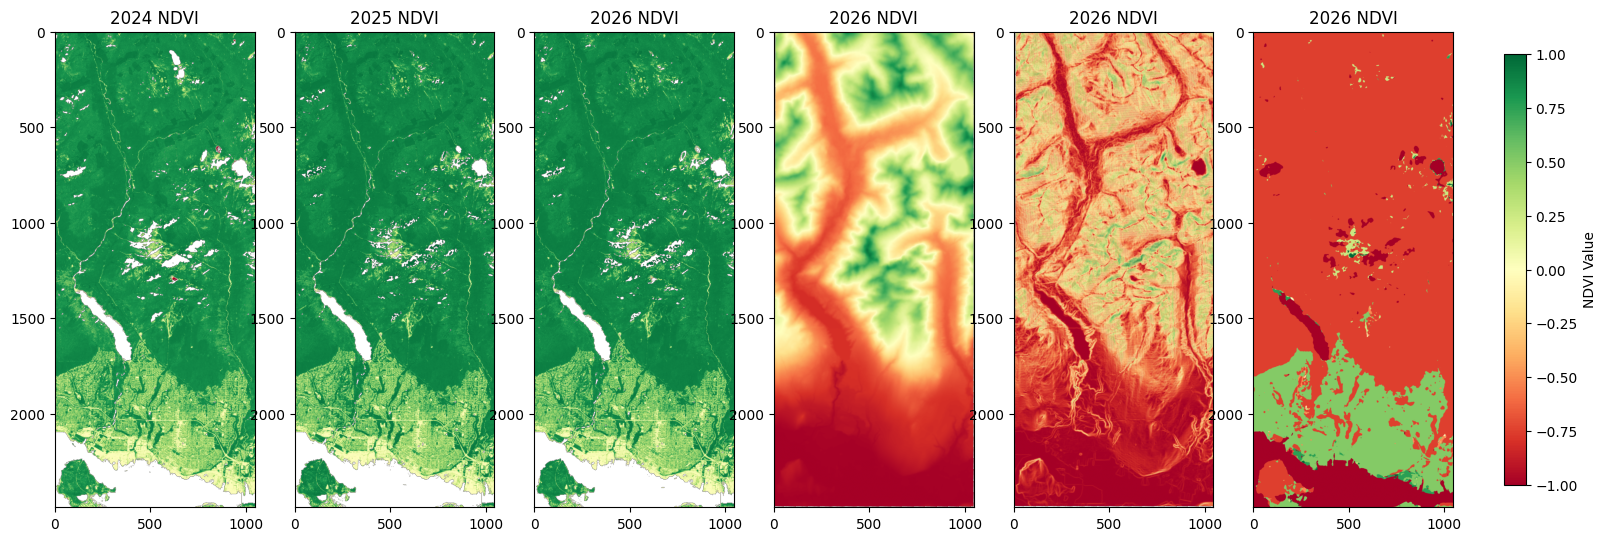

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(22, 8), dpi=100)
cmap = "RdYlGn"

im = axes[0].imshow(ndvi_2024_crop, cmap=cmap, vmin=-1, vmax=1)
axes[0].set_title("2024 NDVI")
axes[1].imshow(ndvi_2025_crop, cmap=cmap, vmin=-1, vmax=1)
axes[1].set_title("2025 NDVI")
axes[2].imshow(ndvi_2026_crop, cmap=cmap, vmin=-1, vmax=1)
axes[2].set_title("2026 NDVI")

axes[3].imshow(elevation_crop, cmap=cmap)
axes[3].set_title("2026 NDVI")
axes[4].imshow(slope_gdal_array, cmap=cmap)
axes[4].set_title("2026 NDVI")
axes[5].imshow(dw_crop, cmap=cmap)
axes[5].set_title("2026 NDVI")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")
plt.show()

## Random Forest ML

In [ ]:
sentinel_2026_B2_corrected_crop = sentinel_2026_B2_corrected[row0:row1, col0:col1]
sentinel_2026_B3_corrected_crop = sentinel_2026_B3_corrected[row0:row1, col0:col1]
sentinel_2026_B4_R_corrected_crop = sentinel_2026_B4_R_corrected[row0:row1, col0:col1]
sentinel_2026_B8_NIR_corrected_crop = sentinel_2026_B8_NIR_corrected[row0:row1, col0:col1]

dw_crop = dw_data[row0:row1, col0:col1]
# elevation_crop = elevation_reproject[row0:row1, col0:col1]
# slope_crop = slope_gdal_array[row0:row1, col0:col1]


for name, data in [
    ("B2", sentinel_2026_B2_corrected_crop),
    ("B3", sentinel_2026_B3_corrected_crop),
    ("B4", sentinel_2026_B4_R_corrected_crop),
    ("B8", sentinel_2026_B8_NIR_corrected_crop),
    ("Dynamic World", dw_crop),
]:
    print(name, data.shape)

dw_v1_2026_mask = (
    np.isfinite(sentinel_2026_B2_corrected_crop)
    & np.isfinite(sentinel_2026_B3_corrected_crop)
    & np.isfinite(sentinel_2026_B4_R_corrected_crop)
    & np.isfinite(sentinel_2026_B8_NIR_corrected_crop)
    & np.isfinite(dw_crop)
    & (dw_crop >= 0)
    & (dw_crop <= 8)
)


sentinel_2026_B2_corrected_crop_mask = sentinel_2026_B2_corrected_crop[dw_v1_2026_mask]
sentinel_2026_B3_corrected_crop_mask = sentinel_2026_B3_corrected_crop[dw_v1_2026_mask]
sentinel_2026_B4_R_corrected_crop_mask = sentinel_2026_B4_R_corrected_crop[dw_v1_2026_mask]
sentinel_2026_B8_NIR_corrected_crop_mask = sentinel_2026_B8_NIR_corrected_crop[dw_v1_2026_mask]
dw_crop_mask = dw_crop[dw_v1_2026_mask]

print(dw_v1_2026_mask.shape)
print(sentinel_2026_B2_corrected_crop_mask.shape)

B2 (2490, 1046)
B3 (2490, 1046)
B4 (2490, 1046)
B8 (2490, 1046)
Dynamic World (2490, 1046)
(2490, 1046)
(2356188,)


In [ ]:
x_features = np.column_stack((sentinel_2026_B2_corrected_crop_mask, sentinel_2026_B3_corrected_crop_mask, sentinel_2026_B4_R_corrected_crop_mask, sentinel_2026_B8_NIR_corrected_crop_mask))
y_labels = dw_crop_mask

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x_features, y_labels,
    test_size=0.2,
    random_state=42,
    stratify=y_labels
)

print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(1884950, 4) (471238, 4) (1884950,) (471238,)


In [ ]:
model_RandFor = RandomForestClassifier(n_estimators=100, random_state=42)
model_RandFor.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_pred = model_RandFor.predict(x_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, labels=range(9)))

Accuracy: 0.7907575365314342
              precision    recall  f1-score   support

           0       0.56      0.21      0.31     31264
           1       0.84      0.94      0.89    345700
           2       0.00      0.00      0.00      1040
           3       0.00      0.00      0.00         0
           4       0.00      0.00      0.00       147
           5       0.15      0.00      0.00      3401
           6       0.57      0.49      0.52     86833
           7       0.03      0.00      0.00      2319
           8       0.09      0.00      0.00       534

    accuracy                           0.79    471238
   macro avg       0.25      0.18      0.19    471238
weighted avg       0.76      0.79      0.77    471238



c:\Users\matil\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\matil\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\matil\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(aver

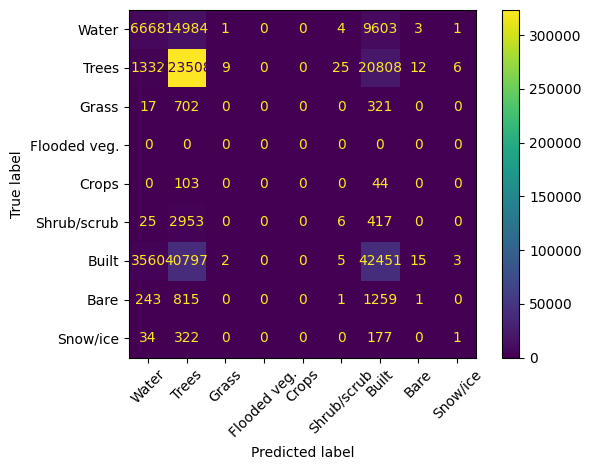

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=range(9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Water", "Trees", "Grass", "Flooded veg.",
        "Crops", "Shrub/scrub", "Built", "Bare", "Snow/ice"
    ]
)

disp.plot(values_format="d", xticks_rotation=45)
plt.tight_layout()
plt.show()

## Lidar

In [ ]:
import laspy
import lazrs

In [ ]:
lidar_path = r"Datasets\lidar\bc_092g034_2_3_2_xyes_8_utm10_20250826_20250826.laz"

In [ ]:
with laspy.open(lidar_path) as src:
    header = src.header

    print("Point count:", header.point_count)
    print("CRS:", header.parse_crs())
    print("Bounds:", header.mins, header.maxs)
    print("Coordinate scales:", header.scales)
    print("Coordinate offsets:", header.offsets)

Point count: 116342
CRS: COMPD_CS["NAD83(CSRS) / UTM zone 10N + CGVD2013(CGG2013) height",
        PROJCS["NAD83(CSRS) / UTM zone 10N",
            GEOGCS["NAD83(CSRS)",
                DATUM["NAD83_Canadian_Spatial_Reference_System",
                    SPHEROID["GRS 1980",6378137,298.257222101,
                    AUTHORITY["EPSG","7019"]],
                AUTHORITY["EPSG","6140"]],
            PRIMEM["Greenwich",0,
                AUTHORITY["EPSG","8901"]],
            UNIT["degree",0.0174532925199433,
                AUTHORITY["EPSG","9122"]],
            AUTHORITY["EPSG","4617"]],
        PROJECTION["Transverse_Mercator"],
        PARAMETER["latitude_of_origin",0],
        PARAMETER["central_meridian",-123],
        PARAMETER["scale_factor",0.9996],
        PARAMETER["false_easting",500000],
        PARAMETER["false_northing",0],
        UNIT["metre",1,
            AUTHORITY["EPSG","9001"]],
        AXIS["Easting",EAST],
        AXIS["Northing",NORTH],
        AUTHORITY["EPSG","31

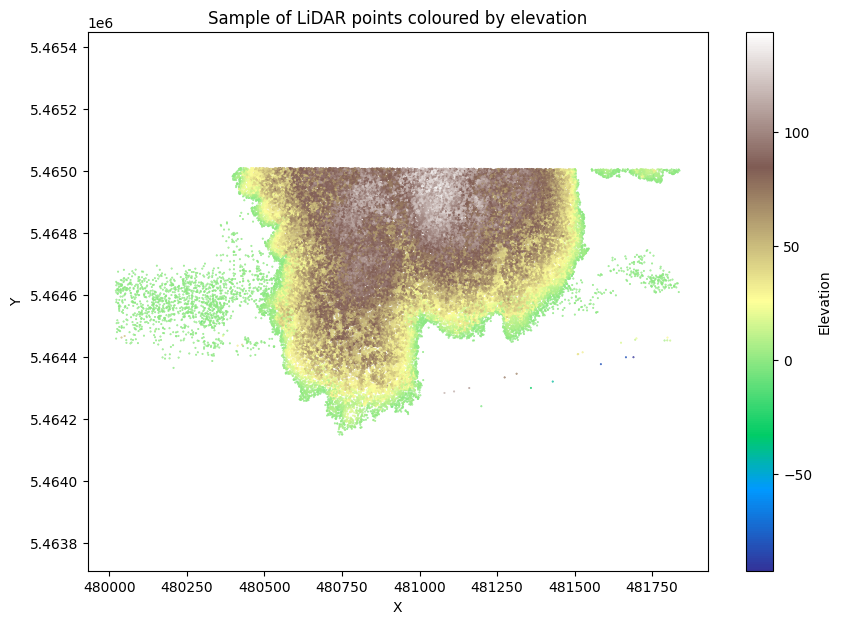

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import laspy

las = laspy.read(lidar_path)

x = np.asarray(las.x)
y = np.asarray(las.y)
z = np.asarray(las.z)

rng = np.random.default_rng(42)
n = min(100_000, len(z))
idx = rng.choice(len(z), size=n, replace=False)

plt.figure(figsize=(10, 7))
plt.scatter(x[idx], y[idx], c=z[idx], s=0.2, cmap="terrain")
plt.colorbar(label="Elevation")
plt.axis("equal")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Sample of LiDAR points coloured by elevation")
plt.show()

In [ ]:
import numpy as np

classes, counts = np.unique(
    las.classification,
    return_counts=True
)

for class_id, count in zip(classes, counts):
    print(f"Class {class_id}: {count:,} points")

print(sum(counts))

Class 1: 25,045,390 points
Class 2: 1,876,020 points
Class 7: 210,040 points
Class 12: 341,413 points
27472863


In [ ]:
print(las.point_format)
print(las.vlrs)

<PointFormat(6, 0 bytes of extra dims)>
[<laspy.vlrs.known.WktCoordinateSystemVlr object at 0x0000019D74219450>, <VLR(user_id: 'province_bc', record_id: '1', data len: 0)>]


In [ ]:
for class_id in classes:
    class_mask = las.classification == class_id
    z_class = np.asarray(las.z)[class_mask]

    print(
        f"Class {class_id}: "
        f"count={len(z_class):,}, "
        f"min_z={z_class.min():.2f}, "
        f"max_z={z_class.max():.2f}"
    )

Class 1: count=25,045,390, min_z=-1.61, max_z=146.23
Class 2: count=1,876,020, min_z=-2.23, max_z=116.78
Class 7: count=210,040, min_z=-98.96, max_z=133.08
Class 12: count=341,413, min_z=-58.43, max_z=126.78


## LiDAR .tif

In [ ]:
from pathlib import Path

path_dir = Path("Datasets") / "lidar"

lidar_files = sorted(path_dir.glob("*.tif"))
print(lidar_files)

lidar_data_col1 = lidar_files[::2]
print(lidar_data_col1)

lidar_data_col2 = lidar_files[1::2]
print(lidar_data_col2)

[WindowsPath('Datasets/lidar/bc_092g005_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g006_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g015_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g016_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g025_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g026_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g035_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g036_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g045_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g046_xl1m_utm10_170713.tif')]
[WindowsPath('Datasets/lidar/bc_092g005_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g015_x1m_utm10_170714.tif'), WindowsPath('Datasets/lidar/bc_092g025_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g035_xl1m_utm10_170713.tif'), WindowsPath('Datasets/lidar/bc_092g045_xl1m_utm10_170713.tif')]
[WindowsPath('Datasets/lidar/bc_092g006_x1m_

In [ ]:
for data in lidar_files:
    with rasterio.open(data) as src1:
        test = src1.read(1)

        print(
            f"{data.name} | "
            f"Type: {type(test).__name__} | "
            f"Size: {test.size} | "
            f"Shape: {test.shape} | "
            f"Min: {test.min()} | "
            f"Max: {test.max()} | "
            f"NoData: {src1.nodata} | "
            f"CRS: {src1.crs} | "
            f"Resolution: {src1.res}"
        )   
             

bc_092g005_x1m_utm10_170714.tif
bc_092g006_x1m_utm10_170714.tif
bc_092g015_x1m_utm10_170714.tif
bc_092g016_x1m_utm10_170714.tif
bc_092g025_xl1m_utm10_170713.tif
bc_092g026_xl1m_utm10_170713.tif
bc_092g035_xl1m_utm10_170713.tif
bc_092g036_xl1m_utm10_170713.tif
bc_092g045_xl1m_utm10_170713.tif
bc_092g046_xl1m_utm10_170713.tif


In [ ]:
| "
            f"Type: {type(test).__name__} | "
            f"Size: {test.size} | "
            f"Shape: {test.shape} | "
            f"Min: {test.min()} | "
            f"Max: {test.max()} | "
            f"NoData: {src1.nodata} | "
            f"CRS: {src1.crs} | "
            f"Resolution: {src1.res}"

In [ ]:
from rasterio.merge import merge

with rasterio.open(lidar_files[0]) as src:
    mosaic, out_transform = merge(
        lidar_files,
        nodata=src.nodata
    )
    profile = src.profile.copy()

profile.update(
    height=mosaic.shape[1],
    width=mosaic.shape[2],
    transform=out_transform
)

output_path = path_dir / "lidar_mosaic.tif"

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(mosaic)

In [ ]:
merged_lidar_data = r"Datasets\lidar\lidar_mosaic.tif"

with rasterio.open(merged_lidar) as src_lidar:
        lidar = src_lidar.read(1)
        lidar_transform = src_lidar.transform
        lidar_crs = src_lidar.crs
        lidar_nodata = src.nodata

        print(
                    f"{data.name} | "
                    f"Type: {type(src_lidar).__name__} | "
                    f"Size: {lidar.size} | "
                    f"Shape: {lidar.shape} | "
                    f"Min: {lidar.min()} | "
                    f"Max: {lidar.max()} | "
                    f"NoData: {src_lidar.nodata} | "
                    f"CRS: {src_lidar.crs} | "
                    f"Resolution: {src_lidar.res}"
                )        

bc_092g046_xl1m_utm10_170713.tif | Type: DatasetReader | Size: 1534874680 | Shape: (52460, 29258) | Min: -32767.0 | Max: 1214.1800537109375 | NoData: -32767.0 | CRS: EPSG:3157 | Resolution: (0.999994999999982, 0.9999949999999207)


In [ ]:
lidar_mask = lidar != lidar_nodata
lidar_clean = np.where(lidar_mask, lidar, np.nan)
print(np.nanmax(lidar_clean))

1214.18


In [ ]:
from rasterio.warp import reproject, Resampling

lidar_reproject = np.empty(sentinel_2026_B4_shape, dtype=np.float32)

reproject(
    source=lidar_clean,
    destination=lidar_reproject,
    src_transform=lidar_transform,
    src_crs=lidar_crs,
    dst_transform=sentinel_2026_B4_transform,
    dst_crs=sentinel_2026_B4_crs,
    dst_nodata=np.nan,
    shape=sentinel_2026_B4_shape,
    resampling=Resampling.nearest
)

print(lidar_reproject.shape)

(11334, 11023)


In [ ]:
lidar_crop = lidar_reproject[row0:row1, col0:col1]
print(lidar_crop.shape)

(2490, 1046)


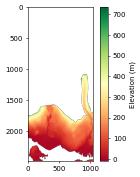

In [ ]:
plt.figure(figsize=(4, 4), dpi=50)
plt.imshow(lidar_crop , cmap="RdYlGn")
plt.colorbar(label="Elevation (m)")
plt.show()

## Band and Blender Exports

In [ ]:
# Flatten the elevation array and filter out NaN values
rows, cols = np.where(np.isfinite(elevation_valid))

x_clean, y_clean = xy(elevation_transform, rows, cols)
z_clean = elevation_valid[rows, cols]
x_clean = np.asarray(x_clean)
y_clean = np.asarray(y_clean)

# Repositon coordinates to Blender origin
origin_x = (x_clean.min() + x_clean.max()) / 2
origin_y = (y_clean.min() + y_clean.max()) / 2
origin_z = z_clean.min()

scale = 100.0  

x_blender = (x_clean - origin_x) / scale
y_blender = (y_clean - origin_y) / scale
z_blender = (z_clean - origin_z) / scale

blender_points = np.column_stack((x_blender, y_blender, z_blender))

print("Cleaned X coordinates:", x_blender)
print("Cleaned Y coordinates:", y_blender)
print("Cleaned Z values:", z_blender)
print(x_blender.shape, y_blender.shape, z_blender.shape)

Cleaned X coordinates: [ 6.45  6.75  7.05 ... -5.85 -5.55 -5.85]
Cleaned Y coordinates: [ 134.1  134.1  134.1 ... -133.8 -133.8 -134.1]
Cleaned Z values: [8.7506075 8.797502  8.883633  ... 0.6188633 0.5860374 0.6770249]
(286497,) (286497,) (286497,)
